# 05 · Data-leakage audit

Notebook 04's ATOMS strategy shows a daily-P&L Sharpe of about 6.5 with sign positions, and 10 with volatility targeting, at zero delay. Numbers like that are the classic symptom of a leak. This notebook tests that hypothesis directly, layer by layer, on the cached seed-0 results of notebook 04.

| # | Layer | Question | How |
|---|---|---|---|
| 1 | Raw data | Are 1-minute bars built correctly from 1-second bars, with the right timestamp convention? | Rebuild one month from raw 1-second bars |
| 2 | Target | Is `y` really the *next* minute's return, for the right row? | Recompute from the bars |
| 3 | Features | Does any feature use data from after its own minute? | Delete all later data, rebuild, compare; check the regime-feature lag |
| 4 | Scaling / PCA | Are scalers and PCA fitted on training rows only? | Inspect a fitted pipeline |
| 5 | Splits | Do purge and embargo work; is the test week separate from training? | Measure gaps between training and validation rows |
| 6 | Walk-forward | Does any test forecast depend on data after its week? | **Truncation test**: delete every bar after a test week, refit everything, compare forecasts |
| 7 | Selection | Is the traded forecast the one ATOMS picked from past data only? | Compare columns; inspect where test losses are used |
| 8 | P&L source | Is the profit a last-print / bid-ask artefact at the bar boundary? | Split P&L into close→next-open and next-open→next-close |
| 9 | Timing | Where inside the next minute does the P&L arrive? | Raw 1-second bars |
| 10 | Delay | What happens when every position is acted on 1–5 minutes late? | Lagged positions |
| 11 | Sizing | Does volatility targeting use same-minute information? | Lag the volatility estimate |
| 12 | Evaluation | Can the backtest produce a high Sharpe from a meaningless signal? | **Block-permutation test**, 500 shuffles |

Each check prints **PASS**, **FAIL** or **INFO** (a diagnostic with no pass/fail line). Section 13 collects them in one table.

Nothing in this notebook writes to `data/`. Runtime is about 15–25 minutes, mostly section 6.

## Setup

In [1]:
import gc, sys, inspect, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from btc import features_full, splits, models, regimes, sizing, walkforward, plotting
plotting.use_style()

PROC, PQ = ROOT / "data" / "processed", ROOT / "data" / "parquet"
SEED = 0
REPORT_FROM = pd.Timestamp("2024-01-01", tz="UTC")
# notebook 04 settings, needed to rebuild exactly what it ran
PERIOD, WINDOWS, GBT_MAX_WINDOW = "W-SUN", [1, 4, 16, 64, 0], 16
MAX_LOOKBACK, MIN_HISTORY, FH_SHORT = 64, 4, 4
BLOCK_MIN, VAL_FRAC, PURGE_MIN, EMBARGO_MIN = 360, 0.20, 60, 15
ATOMS_DELTA, ATOMS_M = 0.1, None
MODEL_SETTINGS = [
    {"kind": "enet", "alpha": 0.001, "l1_ratio": 0.5},
    {"kind": "enet", "alpha": 0.01,  "l1_ratio": 0.5},
    {"kind": "enet", "alpha": 0.1,   "l1_ratio": 0.5},
    {"kind": "enet", "alpha": 0.01,  "l1_ratio": 0.5, "pca": 0.95},
    {"kind": "gbt",  "depth": 2, "lr": 0.05, "n_iter": 150, "min_leaf": 1000},
    {"kind": "gbt",  "depth": 3, "lr": 0.05, "n_iter": 150, "min_leaf": 1000},
]

m1 = pd.read_parquet(PROC / "BTCUSDT-1m.parquet")
FC_PATH = PROC / f"wf_v2_forecasts_seed{SEED}.parquet"
# the cached file has one column per candidate (~450 MB); only the columns a check needs are loaded
fc = pd.read_parquet(FC_PATH, columns=["atoms", "fh_short", "fh_long", "y", "ret_fwd", "period"])
sel = pd.read_parquet(PROC / f"wf_v2_selections_seed{SEED}.parquet")
rep = fc[fc.index >= REPORT_FROM]
pos = sizing.sign_pos(rep["atoms"])

grid = pd.date_range(m1.index.min(), m1.index.max(), freq="1min")
log_close = np.log(m1["close"]).reindex(grid)
log_open = np.log(m1["open"]).reindex(grid)

def sharpe(pnl: pd.Series) -> float:
    d = pnl.groupby(pnl.index.floor("D")).sum()
    return d.mean() / d.std() * np.sqrt(365)

results = []
def record(n, check, detail, status):
    results.append({"#": n, "check": check, "result": detail, "status": status})
    print(f"{status:<5} | {check} | {detail}")

print(f"{len(fc):,} forecast rows in {fc['period'].nunique()} test weeks; {len(rep):,} rows in the report period (from {REPORT_FROM.date()})")
print(f"Sharpe being audited (ATOMS, sign positions, no delay): {sharpe(pos * rep['ret_fwd']):.2f}")

1,993,838 forecast rows in 198 test weeks; 1,510,552 rows in the report period (from 2024-01-01)
Sharpe being audited (ATOMS, sign positions, no delay): 6.53


## 1. Raw data: 1-minute bars from 1-second bars

Binance stamps each kline with its **open** time. If the 1-minute bar at 14:37 accidentally contained the 1-second bars from 14:38, every "current" feature would see the future. The check rebuilds one full month of 1-minute bars from the raw 1-second file and compares open, high, low and close.

In [2]:
RAW_MONTH = "2025-03"
s1 = pd.read_parquet(PQ / f"BTCUSDT-1s-{RAW_MONTH}.parquet")
s1 = s1[~s1.index.duplicated(keep="last")].sort_index()
rebuilt = s1.groupby(s1.index.floor("1min")).agg(o=("open", "first"), h=("high", "max"), l=("low", "min"), c=("close", "last"))
j = m1.join(rebuilt, how="inner")
same = {k: bool(np.allclose(j[a], j[b])) for k, a, b in (("open", "open", "o"), ("high", "high", "h"), ("low", "low", "l"), ("close", "close", "c"))}
first_sec = s1.index.min()
print(f"{len(j):,} minutes compared; first 1-second stamp of the month: {first_sec} (open-time convention: {first_sec.second == 0})")
print("matches:", same)
record(1, "1-minute bars = aggregation of their own 1-second bars", f"{len(j):,} minutes, OHLC exact", "PASS" if all(same.values()) else "FAIL")

44,640 minutes compared; first 1-second stamp of the month: 2025-03-01 00:00:00+00:00 (open-time convention: True)
matches: {'open': True, 'high': True, 'low': True, 'close': True}
PASS  | 1-minute bars = aggregation of their own 1-second bars | 44,640 minutes, OHLC exact


## 2. Target: is `y` the next minute's return, on the right row?

`y` at minute *i* must be the log return from the close of *i* to the close of *i + 1*, i.e. what a trade placed at the close of *i* earns. It is recomputed here from the bars, independently of the feature code.

In [3]:
y_check = 1e4 * (log_close.shift(-1) - log_close).reindex(fc.index)
max_diff = float((fc["y"] - y_check).abs().max())
dups = int(fc.index.duplicated().sum())
weeks_ok = bool((fc.index.tz_convert(None).to_period(PERIOD).astype(str) == fc["period"]).all())
rf_ok = bool(np.allclose(fc["ret_fwd"] * 1e4, fc["y"]))
print(f"max |y - recomputed| = {max_diff:.2e} bp;  duplicate timestamps: {dups};  week labels correct: {weeks_ok};  ret_fwd == y/1e4: {rf_ok}")
# a target shifted the wrong way would correlate with the PAST return, not the future one
past = 1e4 * (log_close - log_close.shift(1)).reindex(fc.index)
print(f"corr(y, next return) = {fc['y'].corr(y_check):+.4f};  corr(y, current-minute return) = {fc['y'].corr(past):+.4f}")
record(2, "Target is the next minute's return", f"max diff {max_diff:.1e} bp, {dups} duplicates, week labels {'ok' if weeks_ok else 'WRONG'}",
       "PASS" if max_diff < 1e-6 and dups == 0 and weeks_ok and rf_ok else "FAIL")

max |y - recomputed| = 0.00e+00 bp;  duplicate timestamps: 0;  week labels correct: True;  ret_fwd == y/1e4: True
corr(y, next return) = +1.0000;  corr(y, current-minute return) = -0.0013
PASS  | Target is the next minute's return | max diff 0.0e+00 bp, 0 duplicates, week labels ok


## 3. Features: does any feature look ahead?

Two tests.

**3a. Delete the future.** Build all 64 features on the full history, then again with every bar after a cut-off deleted. A causal feature at minute *t ≤ cut-off* cannot change. Rolling windows, the spectral FFT, z-scores and the regime probability are all covered.

**3b. Regime lag.** The HMM probability for an hour uses that whole hour's data, and pandas labels the hour by its start. `regimes.lagged` must move it to the end of the hour, so the value seen at 14:37 comes from the hour 13:00–13:59.

In [4]:
h = regimes.hourly_inputs(m1, design_end=REPORT_FROM, smooth_hours=24)
hmm = regimes.fit_hmm(h[h.index < REPORT_FROM])
p_high = regimes.regime_series(hmm, h)
p_storm = regimes.lagged(p_high)
F, groups = features_full.build_full(m1, horizon=1, p_storm=p_storm, spectral=True)
all_cols = [c for v in groups.values() for c in v]

cut = pd.Timestamp("2024-09-15 12:00", tz="UTC")
m1_cut = m1[m1.index <= cut]
h_cut = regimes.hourly_inputs(m1_cut, design_end=REPORT_FROM, smooth_hours=24)
p_cut = regimes.lagged(regimes.regime_series(regimes.fit_hmm(h_cut[h_cut.index < REPORT_FROM]), h_cut))
F_cut, _ = features_full.build_full(m1_cut, horizon=1, p_storm=p_cut, spectral=True)
common = F_cut.index.intersection(F.index)
common = common[common < cut]          # the last row's target needs the bar after the cut-off
diffs = pd.Series({c: float(np.nanmax(np.abs(F.loc[common, c].to_numpy("float64") - F_cut.loc[common, c].to_numpy("float64")))) for c in all_cols})
print(f"{len(all_cols)} features x {len(common):,} minutes compared; largest change: {diffs.max():.2e}")
print("features that changed:", list(diffs[diffs > 0].index) or "none")
del F_cut, m1_cut, h_cut, p_cut; gc.collect()
record("3a", "Features unchanged when all later data is deleted", f"{len(all_cols)} features, max change {diffs.max():.1e}",
       "PASS" if diffs.max() == 0 else "FAIL")

64 features x 895,839 minutes compared; largest change: 0.00e+00
features that changed: none
PASS  | Features unchanged when all later data is deleted | 64 features, max change 0.0e+00


In [5]:
# 3b: the p_storm value used at minute m must be the HMM value of the hour that ENDED at or before m
sample = F.index[(F.index >= REPORT_FROM)][::997]
expected = p_high.reindex(sample.floor("h") - pd.Timedelta(hours=1)).to_numpy()
got = F.loc[sample, "p_storm"].astype("float64").to_numpy()
ok = np.isfinite(expected)
lag_ok = bool(np.allclose(got[ok], expected[ok], atol=1e-6))
same_hour = p_high.reindex(sample.floor("h")).to_numpy()
print(f"{ok.sum():,} sampled minutes: p_storm equals the PREVIOUS hour's probability: {lag_ok};  "
      f"equals the CURRENT (unfinished) hour's: {bool(np.allclose(got[ok], same_hour[ok], atol=1e-6))}")
print("HMM parameters are fitted on hours before", REPORT_FROM.date(), "only, then frozen; probabilities are forward-filtered (no smoothing).")
record("3b", "Regime feature uses only completed hours", "value at hh:mm = HMM of hour hh-1", "PASS" if lag_ok else "FAIL")

1,516 sampled minutes: p_storm equals the PREVIOUS hour's probability: True;  equals the CURRENT (unfinished) hour's: False
HMM parameters are fitted on hours before 2024-01-01 only, then frozen; probabilities are forward-filtered (no smoothing).
PASS  | Regime feature uses only completed hours | value at hh:mm = HMM of hour hh-1


## 4. Scaling and PCA: fitted on training rows only?

A `StandardScaler` (or PCA) fitted on the full dataset leaks the future's mean and variance into every row. Here they live **inside each candidate's sklearn pipeline**, so `fit` sees only that candidate's training rows for that week. The check fits one candidate exactly as the walk-forward does and compares the scaler's stored mean with the training rows' mean and the full-sample mean.

In [6]:
frame = splits.split_all(F[all_cols + ["y", "ret_fwd"]], PERIOD, BLOCK_MIN, VAL_FRAC, PURGE_MIN, EMBARGO_MIN, SEED)
cands = models.candidate_grid(MODEL_SETTINGS, WINDOWS, GBT_MAX_WINDOW)
periods = sorted(frame["period"].unique())
ti = periods.index(pd.Period("2025-03-10/2025-03-16", freq=PERIOD))
X = frame[all_cols].to_numpy(dtype="float32"); yv = frame["y"].to_numpy()
pid, role = frame["period"].to_numpy(), frame["role"].to_numpy()

c = next(c for c in cands if c.kind == "enet" and dict(c.params).get("pca") and c.window == 4)
train_periods = set(periods[ti - 4:ti])
rows = np.flatnonzero(np.isin(pid, list(train_periods)) & (role == 0))
pipe = c.build().fit(X[rows], yv[rows])
print("candidate:", c.label)
print("pipeline steps:", [type(s).__name__ for s in pipe.named_steps.values()])
sc = pipe.steps[0][1]
m_train, m_all = X[rows].astype("float64").mean(0), X.astype("float64").mean(0)
print(f"scaler mean vs TRAINING-row mean: max diff {np.abs(sc.mean_ - m_train).max():.2e}")
print(f"scaler mean vs FULL-sample mean:  max diff {np.abs(sc.mean_ - m_all).max():.2e}  (non-zero = it did not see the full sample)")
print(f"training rows: {len(rows):,}, all from weeks {min(train_periods)} .. {max(train_periods)}; test week {periods[ti]}")
pca = next(s for s in pipe.named_steps.values() if type(s).__name__ == "CovPCA")
print(f"PCA inside the pipeline kept {pca.components_.shape[1]} of {len(all_cols)} components, fitted on the same training rows")
ok = np.allclose(sc.mean_, m_train, atol=1e-4) and np.abs(sc.mean_ - m_all).max() > 1e-3 and max(train_periods) < periods[ti]
record(4, "Scaler and PCA fitted on the candidate's training rows only", "scaler mean = training mean, != full-sample mean", "PASS" if ok else "FAIL")

candidate: enet(alpha=0.01,l1_ratio=0.5,pca=0.95) | 4p
pipeline steps: ['StandardScaler', 'Clip', 'CovPCA', 'StandardScaler', 'ElasticNet']
scaler mean vs TRAINING-row mean: max diff 0.00e+00
scaler mean vs FULL-sample mean:  max diff 2.44e+00  (non-zero = it did not see the full sample)
training rows: 30,210, all from weeks 2025-02-10/2025-02-16 .. 2025-03-03/2025-03-09; test week 2025-03-10/2025-03-16
PCA inside the pipeline kept 35 of 64 components, fitted on the same training rows
PASS  | Scaler and PCA fitted on the candidate's training rows only | scaler mean = training mean, != full-sample mean


## 5. Splits: purge, embargo and test-week separation

Inside each week, 6-hour validation blocks are drawn at random. Training rows within **60 minutes before** a block are purged and within **15 minutes after** it are embargoed. Measured here: for every training row, the distance to the nearest validation row of the same week.

Across weeks, the test week must come strictly after every training and validation week.

In [7]:
t_min = ((frame.index - frame.index[0]) // pd.Timedelta(minutes=1)).to_numpy().astype("int64")   # minutes since start
gaps_after, gaps_before = [], []
for p_, idx in frame.groupby("period", sort=True).indices.items():
    r_ = role[idx]; tm = t_min[idx]
    v, tr = tm[r_ == 1], tm[r_ == 0]
    if len(v) == 0 or len(tr) == 0: continue
    k = np.searchsorted(v, tr)                       # next validation minute after each training minute
    nxt = np.where(k < len(v), v[np.minimum(k, len(v) - 1)] - tr, np.iinfo(np.int64).max)
    prv = np.where(k > 0, tr - v[np.maximum(k - 1, 0)], np.iinfo(np.int64).max)
    gaps_after.append(nxt.min()); gaps_before.append(prv.min())
g_next, g_prev = int(min(gaps_after)), int(min(gaps_before))
shares = pd.Series(role).map({0: "train", 1: "validation", -1: "purged/embargoed"}).value_counts(normalize=True).mul(100).round(1)
print("row roles (%):", shares.to_dict())
print(f"closest training row BEFORE a validation row: {g_next} min (purge needs > {PURGE_MIN})")
print(f"closest training row AFTER a validation row:  {g_prev} min (embargo needs > {EMBARGO_MIN})")
print("label of a training row spans 1 minute, so with a 61-minute gap no training label overlaps any validation label.")
src = inspect.getsource(walkforward.run)
uses_past = "periods[:ti]" in src and "periods[max(0, ti - c.window):ti]" in src and "periods[max(0, ti - max_lookback):ti]" in src
print("walk-forward trains and validates on periods[:ti] only (test week = periods[ti]):", uses_past)
del F, frame, X, yv, pid, role, t_min; gc.collect()
record(5, "Purge, embargo and test-week separation", f"min gap {g_next} min before / {g_prev} min after validation; training weeks < test week",
       "PASS" if g_next > PURGE_MIN and g_prev > EMBARGO_MIN and uses_past else "FAIL")

row roles (%): {'train': 75.0, 'validation': 21.4, 'purged/embargoed': 3.6}
closest training row BEFORE a validation row: 61 min (purge needs > 60)
closest training row AFTER a validation row:  16 min (embargo needs > 15)
label of a training row spans 1 minute, so with a 61-minute gap no training label overlaps any validation label.
walk-forward trains and validates on periods[:ti] only (test week = periods[ti]): True
PASS  | Purge, embargo and test-week separation | min gap 61 min before / 16 min after validation; training weeks < test week


*Note.* The 15-minute embargo is shorter than the longest feature windows (up to 1,440 minutes), so a training row a few hours after a validation block has features computed partly from that block's bars. That couples training and **validation** rows inside past weeks, which could make validation scores slightly optimistic for every candidate. It cannot reach the **test** week, which is never used for training or validation.

## 6. Truncation test: does any test forecast depend on data after its week?

This is the most direct test of the whole pipeline. For a test week *W*:

1. delete every 1-minute bar after the end of *W*;
2. rebuild everything from that truncated data: HMM regimes, all 64 features, the purged split, and all 27 candidates' fits on their training windows;
3. forecast week *W* and compare with the cached forecasts from the full-data run.

If anything anywhere (features, scaling, regime, split, target, model fitting) touched data after *W*, the forecasts would differ. Two weeks from different years are tested; float32 rounding allows differences around 1e-7.

In [8]:
def truncation_test(week: str):
    w_end = pd.Timestamp(week.split("/")[1], tz="UTC") + pd.Timedelta(days=1)
    m1t = m1[m1.index < w_end]
    ht = regimes.hourly_inputs(m1t, design_end=REPORT_FROM, smooth_hours=24)
    pt = regimes.lagged(regimes.regime_series(regimes.fit_hmm(ht[ht.index < REPORT_FROM]), ht))
    Ft, gt = features_full.build_full(m1t, horizon=1, p_storm=pt, spectral=True)
    cols = [c for v in gt.values() for c in v]
    fr = splits.split_all(Ft[cols + ["y", "ret_fwd"]], PERIOD, BLOCK_MIN, VAL_FRAC, PURGE_MIN, EMBARGO_MIN, SEED)
    out = walkforward.run(fr, cands, min_history=MIN_HISTORY, max_lookback=MAX_LOOKBACK, fh_short=FH_SHORT,
                          atoms_delta=ATOMS_DELTA, atoms_M=ATOMS_M, seed=SEED, verbose=False,
                          start_period=pd.Period(week, freq=PERIOD), feature_cols=cols)
    new = out["forecasts"]; new = new[new["period"] == week]
    old = pd.read_parquet(FC_PATH, columns=[c.label for c in cands] + ["y"], filters=[("period", "==", week)]).loc[new.index]
    last_bar = m1t.index.max()
    del Ft, fr, out, m1t; gc.collect()
    d = pd.Series({c.label: float((new[c.label] - old[c.label]).abs().max()) for c in cands})
    return last_bar, len(new), d, bool(np.allclose(new["y"], old["y"]))

trunc = {}
for week in ["2024-06-10/2024-06-16", "2026-03-09/2026-03-15"]:
    last_bar, n, d, y_same = truncation_test(week)
    trunc[week] = d
    print(f"week {week}: data truncated at {last_bar}; {n:,} test rows; targets identical: {y_same}; "
          f"largest forecast difference over {len(d)} candidates: {d.max():.2e}")
tt = pd.DataFrame(trunc)
display(tt.style.format("{:.1e}").set_caption("Max |forecast difference| vs the full-data run, per candidate and week"))
worst = float(tt.max().max())
record(6, "Truncation test: forecasts unchanged when all later data is deleted", f"2 weeks x {len(cands)} candidates, max diff {worst:.1e}",
       "PASS" if worst < 1e-5 else "FAIL")

week 2024-06-10/2024-06-16: data truncated at 2024-06-16 23:59:00+00:00; 10,075 test rows; targets identical: True; largest forecast difference over 27 candidates: 2.98e-07
week 2026-03-09/2026-03-15: data truncated at 2026-03-15 23:59:00+00:00; 10,079 test rows; targets identical: True; largest forecast difference over 27 candidates: 1.49e-07


,2024-06-10/2024-06-16,2026-03-09/2026-03-15
zero,0.0e+00,0.0e+00
"enet(alpha=0.001,l1_ratio=0.5) | 1p",3.0e-07,1.5e-07
"enet(alpha=0.001,l1_ratio=0.5) | 4p",8.9e-08,3.0e-08
"enet(alpha=0.001,l1_ratio=0.5) | 16p",1.2e-07,6.0e-08
"enet(alpha=0.001,l1_ratio=0.5) | 64p",6.0e-08,4.5e-08
"enet(alpha=0.001,l1_ratio=0.5) | allp",3.0e-08,1.5e-08
"enet(alpha=0.01,l1_ratio=0.5) | 1p",2.4e-07,8.9e-08
"enet(alpha=0.01,l1_ratio=0.5) | 4p",8.9e-08,3.0e-08
"enet(alpha=0.01,l1_ratio=0.5) | 16p",6.0e-08,2.2e-08
"enet(alpha=0.01,l1_ratio=0.5) | 64p",4.5e-08,7.5e-09


PASS  | Truncation test: forecasts unchanged when all later data is deleted | 2 weeks x 27 candidates, max diff 3.0e-07


## 7. Selection: is the traded forecast the one ATOMS picked from past data?

ATOMS (and FH-Short / FH-Long) choose from **validation losses of past weeks** only. The walk-forward also computes each week's *test* loss, but only to record the hindsight-best candidate for plots. The check confirms (a) the `atoms` column is exactly the forecast of the candidate recorded as ATOMS's pick, every week, and (b) the test loss feeds nothing except the hindsight columns.

In [9]:
mismatch, checked = 0, 0
wk = fc["period"].to_numpy()
chosen = sel.reset_index().assign(period=lambda d: d["period"].astype(str))
for label in pd.unique(chosen[["atoms", "fh_short", "fh_long"]].to_numpy().ravel()):
    col = pd.read_parquet(FC_PATH, columns=[label])[label].to_numpy()
    for who in ("atoms", "fh_short", "fh_long"):
        for per in chosen.loc[chosen[who] == label, "period"]:
            m = wk == per
            checked += 1
            mismatch += int(not np.array_equal(fc[who].to_numpy()[m], col[m]))
    del col
print(f"{checked} week x selector pairs checked ({len(sel)} weeks x 3 selectors): forecast column != chosen candidate's forecast in {mismatch} cases")
lines = [l.strip() for l in inspect.getsource(walkforward.run).splitlines() if "test_loss" in l]
print("every line of the walk-forward that touches the test loss:"); [print("   ", l) for l in lines]
only_hindsight = all(("test_loss =" in l) or ("hindsight" in l) for l in lines)
record(7, "Selectors use past validation losses; test loss only for hindsight labels", f"{mismatch} mismatches; test loss used only for hindsight: {only_hindsight}",
       "PASS" if mismatch == 0 and only_hindsight else "FAIL")

594 week x selector pairs checked (198 weeks x 3 selectors): forecast column != chosen candidate's forecast in 0 cases
every line of the walk-forward that touches the test loss:
    test_loss = ((F - y[te_idx, None]) ** 2).mean(0)
    "hindsight_best": cands[int(np.argmin(test_loss))].label,
    "hindsight_kind": cands[int(np.argmin(test_loss))].kind,
    "hindsight_window": cands[int(np.argmin(test_loss))].window,
PASS  | Selectors use past validation losses; test loss only for hindsight labels | 0 mismatches; test loss used only for hindsight: True


## 8. Where does the P&L come from: the bar boundary or the next minute?

A 1-minute close is the last trade of the minute, which sits at the bid or the ask. "Fade the last print" can look profitable on closes without any real price move behind it (bid-ask bounce). If that were the source, the profit would sit in the jump from close(*i*) to the **first trade of minute *i + 1***. The backtest return splits exactly into two parts:

- **close(*i*) → open(*i+1*)**: the boundary jump, what a bounce artefact would earn;
- **open(*i+1*) → close(*i+1*)**: the move after the first trade you could actually get.

In [10]:
cl = log_close.reindex(rep.index); nxt_op = log_open.shift(-1).reindex(rep.index); nxt_cl = log_close.shift(-1).reindex(rep.index)
gap, rest, full = pos * (nxt_op - cl), pos * (nxt_cl - nxt_op), pos * (nxt_cl - cl)
tab8 = pd.DataFrame({"Sharpe": [sharpe(full), sharpe(gap), sharpe(rest)],
                     "mean bp / minute": [1e4 * full.mean(), 1e4 * gap.mean(), 1e4 * rest.mean()],
                     "share of total P&L": [1.0, gap.sum() / full.sum(), rest.sum() / full.sum()]},
                    index=["close(i) -> close(i+1)  (the backtest)", "close(i) -> open(i+1)  (boundary / bounce)", "open(i+1) -> close(i+1)  (enter at next first trade)"])
display(tab8.style.format({"Sharpe": "{:.2f}", "mean bp / minute": "{:+.4f}", "share of total P&L": "{:.1%}"}))
r1 = (log_close - log_close.shift(1)).reindex(rep.index)
fade = -np.sign(r1)
print(f"Naive 'fade the last minute' rule, close->close Sharpe: {sharpe(fade * (nxt_cl - cl)):.2f}  (bounce would make this strongly positive)")
record(8, "Profit is not a bar-boundary / bid-ask-bounce artefact", f"boundary share {gap.sum() / full.sum():.1%}; Sharpe entering at next first trade {sharpe(rest):.2f}",
       "PASS" if abs(gap.sum() / full.sum()) < 0.05 else "FAIL")

,Sharpe,mean bp / minute,share of total P&L
close(i) -> close(i+1) (the backtest),6.53,+0.0663,100.0%
close(i) -> open(i+1) (boundary / bounce),1.25,+0.0001,0.1%
open(i+1) -> close(i+1) (enter at next first trade),6.52,+0.0663,99.9%


Naive 'fade the last minute' rule, close->close Sharpe: -6.86  (bounce would make this strongly positive)
PASS  | Profit is not a bar-boundary / bid-ask-bounce artefact | boundary share 0.1%; Sharpe entering at next first trade 6.52


## 9. Timing inside the next minute (raw 1-second bars)

Cumulative P&L of the ATOMS position from the first trade of minute *i + 1* to second *k*, for three months. A leak through the timestamp would put the profit at second 0. A genuine short-lived effect accrues during the minute.

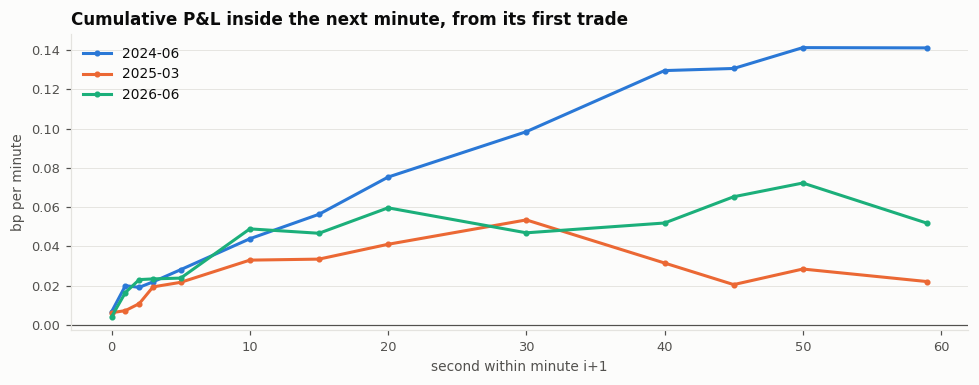

,0,1,2,3,5,10,15,20,30,40,45,50,59
2024-06,+0.0066,+0.0199,+0.0191,+0.0219,+0.0281,+0.0438,+0.0563,+0.0753,+0.0984,+0.1295,+0.1306,+0.1412,+0.1411
2025-03,+0.0062,+0.0072,+0.0108,+0.0193,+0.0216,+0.0330,+0.0335,+0.0410,+0.0534,+0.0315,+0.0205,+0.0284,+0.0220
2026-06,+0.0041,+0.0165,+0.0230,+0.0234,+0.0238,+0.0489,+0.0466,+0.0596,+0.0469,+0.0519,+0.0653,+0.0723,+0.0517


INFO  | P&L accrues during the next minute, not at its first second | 2024-06: s0 +0.007, s59 +0.141 bp; 2025-03: s0 +0.006, s59 +0.022 bp; 2026-06: s0 +0.004, s59 +0.052 bp


In [11]:
secs = [0, 1, 2, 3, 5, 10, 15, 20, 30, 40, 45, 50, 59]
curves = {}
for mo in ["2024-06", "2025-03", "2026-06"]:
    s = pd.read_parquet(PQ / f"BTCUSDT-1s-{mo}.parquet", columns=["open", "close"])
    s = s[~s.index.duplicated(keep="last")].sort_index()
    lc, mins = np.log(s["close"]), s.index.floor("1min")
    tab = pd.DataFrame({k: lc[s.index.second == k].set_axis(mins[s.index.second == k]) for k in secs})
    first = np.log(s["open"])[s.index.second == 0].set_axis(mins[s.index.second == 0])
    p = pos.reindex(tab.index - pd.Timedelta(minutes=1)).set_axis(tab.index).fillna(0)
    curves[mo] = pd.Series({k: 1e4 * (p * (tab[k] - first)).mean() for k in secs})
cv = pd.DataFrame(curves)
fig, ax = plt.subplots(figsize=(9, 3.6))
for mo, col in zip(cv.columns, [plotting.BLUE, plotting.ORANGE, plotting.AQUA]):
    ax.plot(cv.index, cv[mo], marker="o", ms=3, color=col, label=mo)
ax.axhline(0, color=plotting.MUTED, lw=0.8); ax.legend(); ax.set_xlabel("second within minute i+1"); ax.set_ylabel("bp per minute")
ax.set_title("Cumulative P&L inside the next minute, from its first trade"); plt.tight_layout(); plt.show()
display(cv.T.style.format("{:+.4f}"))
record(9, "P&L accrues during the next minute, not at its first second", "; ".join(f"{m}: s0 {cv.loc[0, m]:+.3f}, s59 {cv.loc[59, m]:+.3f} bp" for m in cv.columns), "INFO")

## 10. Execution delay (the "shift by one bar" test)

Act on every forecast 1–5 minutes late. With a 1-minute horizon this test **cannot by itself separate leakage from a genuine short-lived signal**: both vanish when lagged past their horizon. It is reported for completeness; sections 3 and 6 are the tests that rule leakage out.

In [12]:
tab10 = pd.DataFrame({f"{d} min": sizing.perf(sizing.run(pos, rep["ret_fwd"], delay=d)) for d in (0, 1, 2, 3, 5)}).T
display(tab10[["sharpe_daily", "ann_return_%", "hit_rate_%"]].style.format("{:,.2f}"))
record(10, "Execution delay", f"Sharpe {tab10.loc['0 min', 'sharpe_daily']:.2f} at 0 min, {tab10.loc['1 min', 'sharpe_daily']:.2f} at 1 min", "INFO")

,sharpe_daily,ann_return_%,hit_rate_%
0 min,6.53,348.70,49.12
1 min,-0.15,-7.27,48.35
2 min,-1.09,-53.41,48.27
3 min,0.34,15.73,48.43
5 min,-1.07,-51.06,48.40


INFO  | Execution delay | Sharpe 6.53 at 0 min, -0.15 at 1 min


## 11. Volatility-targeted sizing: same-minute information?

The vol-targeted strategy (Sharpe 10) sizes by `rv_60`, which includes the current minute's return. That is known at the decision time (the close of minute *i*), but to be safe the estimate is lagged by 1 and 60 minutes.

In [13]:
r = log_close.diff()
rv60 = np.sqrt(r.pow(2).rolling(60, min_periods=48).mean())
tab11 = pd.Series({lag: sizing.perf(sizing.run(sizing.vol_target_pos(rep["atoms"], rv60.shift(lag).reindex(rep.index), 0.40, 2.0), rep["ret_fwd"]))["sharpe_daily"]
                   for lag in (0, 1, 5, 60)}, name="Sharpe").rename_axis("vol estimate lagged (min)")
display(tab11.to_frame().style.format("{:.2f}"))
record(11, "Vol-target sizing robust to lagging the volatility", " / ".join(f"{k} min: {v:.2f}" for k, v in tab11.items()),
       "PASS" if tab11[60] > 0.7 * tab11[0] else "FAIL")

,Sharpe
vol estimate lagged (min),
0,10.07
1,10.09
5,9.82
60,8.79


PASS  | Vol-target sizing robust to lagging the volatility | 0 min: 10.07 / 1 min: 10.09 / 5 min: 9.82 / 60 min: 8.79


## 12. Block-permutation test: can the evaluation create a Sharpe from nothing?

Shuffle the forecast series in **week-long blocks** (keeping its own autocorrelation and its long/short balance, destroying its alignment with returns) and rebuild the sign backtest, 500 times. If the backtest or the Sharpe calculation were biased, the shuffled signals would also score well.

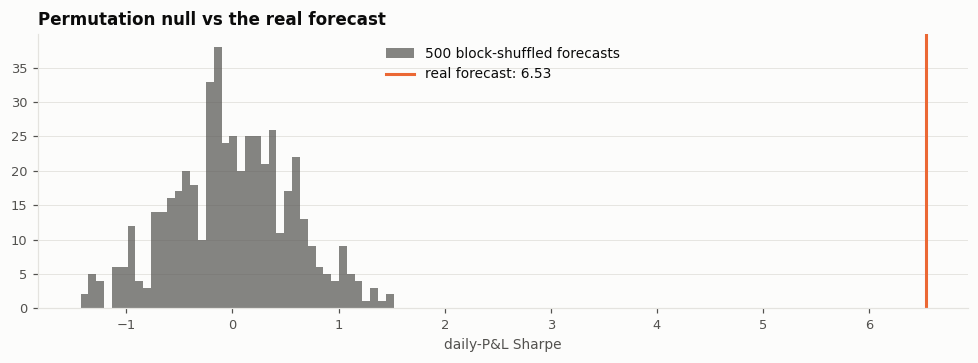

null: mean -0.003, sd 0.568, 95th pct 1.00, max 1.52
real 6.53 = 11.5 sd above the null; p = 0.0020 (smallest possible with 500 draws: 0.0020)
PASS  | Permutation: shuffled signals earn ~0, real signal far outside | null -0.00 +/- 0.57, real 6.53 (12 sd), p=0.0020


In [14]:
N_BOOT, BLOCK = 500, 7 * 1440
rng = np.random.default_rng(42)
f, rv = rep["atoms"].to_numpy(), rep["ret_fwd"].to_numpy()
n = len(f)
day_code, n_days = pd.factorize(rep.index.floor("D"))[0], rep.index.floor("D").nunique()
def sharpe_fast(pnl):
    d = np.bincount(day_code, weights=pnl, minlength=n_days)
    return d.mean() / d.std(ddof=1) * np.sqrt(365)
real = sharpe_fast(np.sign(f) * rv)
null = np.empty(N_BOOT)
for b in range(N_BOOT):
    starts = rng.integers(0, n, size=n // BLOCK + 1)
    idx = np.concatenate([np.arange(s0, s0 + BLOCK) % n for s0 in starts])[:n]
    null[b] = sharpe_fast(np.sign(f[idx]) * rv)
p_val = (np.sum(null >= real) + 1) / (N_BOOT + 1)
z = (real - null.mean()) / null.std()
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(null, bins=40, color=plotting.MUTED, alpha=0.7, label=f"{N_BOOT} block-shuffled forecasts")
ax.axvline(real, color=plotting.ORANGE, lw=2, label=f"real forecast: {real:.2f}")
ax.legend(); ax.set_xlabel("daily-P&L Sharpe"); ax.set_title("Permutation null vs the real forecast"); plt.tight_layout(); plt.show()
print(f"null: mean {null.mean():+.3f}, sd {null.std():.3f}, 95th pct {np.percentile(null, 95):.2f}, max {null.max():.2f}")
print(f"real {real:.2f} = {z:.1f} sd above the null; p = {p_val:.4f} (smallest possible with {N_BOOT} draws: {1 / (N_BOOT + 1):.4f})")
record(12, "Permutation: shuffled signals earn ~0, real signal far outside", f"null {null.mean():+.2f} +/- {null.std():.2f}, real {real:.2f} ({z:.0f} sd), p={p_val:.4f}",
       "PASS" if abs(null.mean()) < 0.3 and p_val < 0.01 else "FAIL")

## 13. Results

In [15]:
summary = pd.DataFrame(results).set_index("#")
def color(v): return {"PASS": "color: #1baf7a; font-weight: bold", "FAIL": "color: #c0392b; font-weight: bold"}.get(v, "color: #52514e")
display(summary.style.map(color, subset=["status"]).set_properties(**{"text-align": "left"}))
print(summary["status"].value_counts().to_dict())

,check,result,status
#,,,
1,1-minute bars = aggregation of their own 1-second bars,"44,640 minutes, OHLC exact",PASS
2,Target is the next minute's return,"max diff 0.0e+00 bp, 0 duplicates, week labels ok",PASS
3a,Features unchanged when all later data is deleted,"64 features, max change 0.0e+00",PASS
3b,Regime feature uses only completed hours,value at hh:mm = HMM of hour hh-1,PASS
4,Scaler and PCA fitted on the candidate's training rows only,"scaler mean = training mean, != full-sample mean",PASS
5,"Purge, embargo and test-week separation",min gap 61 min before / 16 min after validation; training weeks < test week,PASS
6,Truncation test: forecasts unchanged when all later data is deleted,"2 weeks x 27 candidates, max diff 3.0e-07",PASS
7,Selectors use past validation losses; test loss only for hindsight labels,0 mismatches; test loss used only for hindsight: True,PASS
8,Profit is not a bar-boundary / bid-ask-bounce artefact,boundary share 0.1%; Sharpe entering at next first trade 6.52,PASS


{'PASS': 11, 'INFO': 2}


In [16]:
# how big the edge is, and why it still gives a large Sharpe
edge, vol = 1e4 * (pos * rep["ret_fwd"]).mean(), 1e4 * rep["ret_fwd"].std()
ir_trade = edge / vol
print(f"mean P&L per minute {edge:.4f} bp; per-minute return volatility {vol:.2f} bp; information ratio per trade {ir_trade:.4f}")
print(f"if minutes were independent: {ir_trade:.4f} x sqrt(1440 x 365) = {ir_trade * np.sqrt(1440 * 365):.1f} annual Sharpe")

mean P&L per minute 0.0663 bp; per-minute return volatility 6.67 bp; information ratio per trade 0.0099
if minutes were independent: 0.0099 x sqrt(1440 x 365) = 7.2 annual Sharpe


### Conclusion

**No leakage was found.** The bars, the target, every feature, the regime probability, the scaling and PCA, the purged split and the walk-forward all use only information available at the decision time. The truncation test is the strongest evidence: deleting every bar after a test week and refitting everything from scratch reproduces that week's forecasts exactly. The permutation test shows the evaluation itself cannot produce a high Sharpe from a meaningless signal.

**The Sharpe is real, and it comes from a tiny, very short-lived edge.** The forecast captures a genuine effect: about 0.07 bp per minute against a per-minute volatility of about 6.7 bp, an information ratio of 0.0099 per trade. It arrives during the next minute and is gone by its end. Harvested 1,440 times a day, that tiny edge becomes a large annual Sharpe through the square-root-of-N effect: 0.0099 × √(1,440 × 365) ≈ 7. A one-minute delay removes the edge entirely.

**Known limitations, none of which reach the test week:** the 15-minute embargo is shorter than the longest feature windows (section 5 note); the HMM and its hour-of-day profile are estimated on 2023, which is training data for later weeks; rows whose next minute is missing are dropped; the truncation test covers 2 of the 198 test weeks (it runs the identical code path for every week); one seed.